## RetailIQ — Machine Learning

This notebook explores machine learning opportunities using the processed RetailIQ dataset.

The objective is to identify a meaningful business prediction problem, prepare an appropriate machine learning dataset, develop predictive models, and evaluate their usefulness from both technical and business perspectives.

The machine learning workflow will focus on:

1. ML problem definition
2. Dataset preparation
3. Baseline modeling
4. Model training and comparison
5. Model evaluation and interpretation
6. Business insights and limitations
7. Documentation and project integration

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/retailiq_order_item_data.csv")

df.shape

(112650, 41)

In [2]:
df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,order_year_month,seller_zip_code_prefix,seller_city,seller_state,total_payment_value,payment_count,primary_payment_type,max_installments,review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,2017-09,27277,volta redonda,SP,72.19,1.0,credit_card,2.0,5.0,1.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,2017-04,3471,sao paulo,SP,259.83,1.0,credit_card,3.0,4.0,1.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,2018-01,37564,borda da mata,MG,216.87,1.0,credit_card,5.0,5.0,1.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,2018-08,14403,franca,SP,25.78,1.0,credit_card,2.0,4.0,1.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,2017-02,87900,loanda,PR,218.04,1.0,credit_card,3.0,5.0,1.0


In [3]:
df.columns.tolist()

['order_id',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'product_category_name',
 'product_category_english',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm',
 'sales',
 'freight',
 'order_value',
 'delivery_days',
 'estimated_delivery_days',
 'delivery_delay_days',
 'delivery_status',
 'order_date',
 'order_year',
 'order_month',
 'order_month_name',
 'order_year_month',
 'seller_zip_code_prefix',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'payment_count',
 'primary_payment_type',
 'max_installments',
 'review_score',
 'review_count']

## 5.1 ML Problem Definition
### Candidate Prediction Problems

Several machine learning opportunities were identified from the RetailIQ dataset:

| Prediction Problem | Target | ML Type | Business Value | Data Suitability |
|---|---|---|---|---|
| Delivery delay prediction | Delivery status | Classification | High | High |
| Delivery duration prediction | Delivery days | Regression | High | High |
| Review score prediction | Review score | Classification / Regression | Medium | Moderate |
| Sales forecasting | Future sales | Time-series forecasting | High | Requires restructuring |

The candidate problems will be evaluated based on:

* Business relevance
* Availability of suitable features
* Predictability of the target
* Risk of data leakage
* Appropriate evaluation methodology
* Practical usefulness of the resulting model

In [4]:
# Examine candidate target variables
# Examine the main target variables being considered for machine learning.
# This helps us understand their distributions, missing values, and basic statistics.
df[['delivery_status', 'delivery_days', 'delivery_delay_days', 'review_score']].describe(
    include='all'
)

,delivery_status,delivery_days,delivery_delay_days,review_score
count,112650,110196.000000,110196.000000,111708.000000
unique,3,NaN,NaN,NaN
top,Early,NaN,NaN,NaN
freq,101481,NaN,NaN,NaN
mean,NaN,12.472631,-11.333149,4.033128
std,NaN,9.445655,10.162342,1.386119
min,NaN,0.533414,-146.016123,1.000000
25%,NaN,6.736262,-16.321042,4.000000
50%,NaN,10.184282,-12.046788,5.000000
75%,NaN,15.541097,-6.476803,5.000000


In [5]:
# Examine delivery outcome distribution
# Count each delivery status, including missing values.
# This helps us determine whether the delivery prediction target is imbalanced.
df['delivery_status'].value_counts(dropna=False)

delivery_status
Early            101481
Delayed            8715
Not Delivered      2454
Name: count, dtype: int64

In [6]:
# Examine review score distribution
# Count each review score, including missing values.
# This helps us assess whether review score is a suitable prediction target.
df['review_score'].value_counts(dropna=False).sort_index()

review_score
1.000000    14079
1.500000       18
2.000000     3833
2.500000       45
3.000000     9384
3.333333        1
3.500000       31
4.000000    21166
4.333333        1
4.500000       68
5.000000    63082
NaN           942
Name: count, dtype: int64

### Relationship Between Delivery Status and Delivery Delay

Before selecting delivery status as a prediction target, the relationship between the target and the underlying delivery-delay metric must be examined.

This helps us understand how the target was constructed and identify variables that could cause data leakage during model training.

In [7]:
# Compare delivery status with the calculated delivery delay.
# This helps us understand how the categorical target relates to the underlying delay metric.
df.groupby('delivery_status')['delivery_delay_days'].agg(
    ['count', 'min', 'mean', 'median', 'max']
)

,count,min,mean,median,max
delivery_status,,,,,
Delayed,8715,0.002500,9.428269,5.779606,188.975081
Early,101481,-146.016123,-13.116102,-12.357384,-0.000058
Not Delivered,0,NaN,NaN,NaN,NaN


In [8]:
# Examine the range of delivery delay values within each delivery status.
# This helps verify whether the categories are clearly separated by delivery performance.
df.groupby('delivery_status')['delivery_delay_days'].describe()

,count,mean,std,min,25%,50%,75%,max
delivery_status,,,,,,,,
Delayed,8715.0,9.428269,13.803611,0.002500,1.858368,5.779606,11.776956,188.975081
Early,101481.0,-13.116102,7.455521,-146.016123,-17.133762,-12.357384,-8.052454,-0.000058
Not Delivered,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Delivery Status and Order Status

The delivery outcome is compared with the original order status to understand which orders were delivered, delayed, or not delivered.

This investigation will help define the population eligible for the delivery prediction task and prevent cancelled or otherwise incomplete orders from being incorrectly labeled.

In [9]:
# Compare original order status with the derived delivery status.
# This helps identify cancelled, unavailable, and other orders without a completed delivery.
pd.crosstab(
    df['order_status'],
    df['delivery_status'],
    margins=True
)

delivery_status,Delayed,Early,Not Delivered,All
order_status,,,,
approved,0,0,3,3
canceled,1,6,535,542
delivered,8714,101475,8,110197
invoiced,0,0,359,359
processing,0,0,357,357
shipped,0,0,1185,1185
unavailable,0,0,7,7
All,8715,101481,2454,112650


### Selected ML Problem: Delivery Delay Prediction

**Business Objective**

Predict whether an e-commerce order will be delivered after its estimated delivery date using information available before the delivery outcome is known.

**Problem Type:** Binary Classification

**Target Variable:** `is_delayed`

- `1`: The order was delivered after the estimated delivery date.
- `0`: The order was delivered on or before the estimated delivery date.

**Eligible Population**

The initial modeling dataset will include orders with `order_status = 'delivered'` and a valid delivery outcome.

**Potential Features**

Purchase date and time, product characteristics, seller information, price, freight charges, payment characteristics, and estimated delivery information, subject to availability at the prediction point.

**Data Leakage Prevention**

Actual delivery timestamps, `delivery_days`, `delivery_delay_days`, and `delivery_status` will not be used as model input features. The target will be derived from the actual delivery outcome, not supplied to the model as a predictor.

**Evaluation Strategy**

Model performance will be evaluated using precision, recall, F1-score, a confusion matrix, and other appropriate metrics. Accuracy alone will not be sufficient because the delivery outcomes are imbalanced.

**Business Value**

The model could help identify orders at higher risk of late delivery, allowing an e-commerce business to investigate potential operational issues and prioritize interventions.

## 5.2 ML Dataset Preparation

The processed RetailIQ dataset contains order-item-level records. Since delivery delay is an order-level outcome, the data must be transformed into one record per order.

Only delivered orders with valid actual and estimated delivery timestamps will be included in the initial modeling dataset.

The binary target will be derived by comparing the actual delivery timestamp with the estimated delivery timestamp. Information describing the eventual delivery outcome will not be used as a model input feature.

In [10]:
# Convert delivery timestamps to datetime format for accurate comparison.
date_cols = [
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Keep only delivered orders with valid actual and estimated delivery dates.
eligible_df = df[
    (df['order_status'] == 'delivered') &
    df['order_delivered_customer_date'].notna() &
    df['order_estimated_delivery_date'].notna()
].copy()

# Create a binary target: 1 = late, 0 = on time or early.
eligible_df['is_delayed'] = (
    eligible_df['order_delivered_customer_date'] >
    eligible_df['order_estimated_delivery_date']
).astype(int)

# Check the eligible records and target distribution.
print("Eligible order-item rows:", len(eligible_df))
print("Unique orders:", eligible_df['order_id'].nunique())
print("\nTarget distribution:")
print(eligible_df['is_delayed'].value_counts())
print("\nTarget proportions:")
print(eligible_df['is_delayed'].value_counts(normalize=True).round(3))

Eligible order-item rows: 110189
Unique orders: 96470

Target distribution:
is_delayed
0    101475
1      8714
Name: count, dtype: int64

Target proportions:
is_delayed
0    0.921
1    0.079
Name: proportion, dtype: float64


In [11]:
# Check how many item rows belong to each order.
items_per_order = eligible_df.groupby('order_id').size()

print("Number of unique orders:", items_per_order.size)
print("Orders with multiple items:", (items_per_order > 1).sum())
print("Maximum items in one order:", items_per_order.max())

Number of unique orders: 96470
Orders with multiple items: 9635
Maximum items in one order: 21


### Order-Level Feature Engineering

Multiple order-item records can belong to the same order. To prevent the same order from appearing multiple times in the modeling dataset, item-level information will be aggregated into a single record per order.

Numerical product and transaction features will be aggregated using suitable summary statistics, while categorical features will be retained or summarized at the order level.

The target will remain constant within each order and will be verified after aggregation.

In [12]:
# Define numerical features to aggregate across items in each order.
numeric_features = [
    'price',
    'freight_value',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

# Define order-level categorical and timestamp features.
categorical_features = [
    'customer_id',
    'order_purchase_timestamp',
    'order_estimated_delivery_date',
    'primary_payment_type',
    'seller_state',
    'product_category_english'
]

# Aggregate item-level data into one row per order.
agg_dict = {
    'is_delayed': 'first',
    'order_purchase_timestamp': 'first',
    'order_estimated_delivery_date': 'first',
    'customer_id': 'first',
    'primary_payment_type': 'first',
    'seller_state': 'first',
    'product_category_english': 'first',
    'order_item_id': 'count'
}

# Add summary statistics for numerical item-level features.
for col in numeric_features:
    agg_dict[col] = 'sum' if col in ['price', 'freight_value'] else 'mean'

order_df = eligible_df.groupby('order_id').agg(agg_dict).reset_index()

# Rename the item count to make its meaning clear.
order_df = order_df.rename(columns={
    'order_item_id': 'item_count',
    'price': 'total_item_price',
    'freight_value': 'total_freight'
})

# Verify that each order appears only once.
print("Order-level dataset shape:", order_df.shape)
print("Unique orders:", order_df['order_id'].nunique())
print("Duplicate order IDs:", order_df['order_id'].duplicated().sum())

# Confirm the target distribution after aggregation.
print("\nTarget distribution:")
print(order_df['is_delayed'].value_counts())
print("\nLate-delivery rate:", round(order_df['is_delayed'].mean() * 100, 2), "%")

Order-level dataset shape: (96470, 15)
Unique orders: 96470
Duplicate order IDs: 0

Target distribution:
is_delayed
0    88644
1     7826
Name: count, dtype: int64

Late-delivery rate: 8.11 %


### Train-Test Split and Feature Preparation

The dataset will be divided into training and test sets using a stratified split to preserve the late-delivery proportion in both sets.

Identifiers and outcome-derived fields will be excluded from model inputs. The test set will remain untouched during model training and comparison.

Categorical and numerical preprocessing will be fitted only on the training data to prevent data leakage.

In [13]:
from sklearn.model_selection import train_test_split

# Create calendar features from the purchase timestamp.
order_df['purchase_month'] = pd.to_datetime(
    order_df['order_purchase_timestamp']
).dt.month

order_df['purchase_day_of_week'] = pd.to_datetime(
    order_df['order_purchase_timestamp']
).dt.dayofweek

# select features that could be available when the order is placed.
feature_cols = [
    'total_item_price',
    'total_freight',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm',
    'item_count',
    'purchase_month',
    'purchase_day_of_week',
    'primary_payment_type',
    'seller_state',
    'product_category_english'
]

# Separate model inputs from the target.
X = order_df[feature_cols].copy()
y = order_df['is_delayed'].copy()

# Split before fitting any preprocessing steps.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Training rows: ", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])
print("Training late-delivery rate: ", round(y_train.mean() * 100, 2), "%")
print("Testing late-delivery rate: ", round(y_test.mean() * 100, 2), "%")

Training rows:  77176
Testing rows:  19294
Training late-delivery rate:  8.11 %
Testing late-delivery rate:  8.11 %


## 5.3 Baseline Model

A majority-class baseline is established to provide a reference point for evaluating more sophisticated models.

Since late deliveries represent a minority of observations, this baseline predicts every order as not delayed. Its performance will demonstrate why accuracy alone is insufficient for evaluating the model.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Train a baseline model that always predicts the majority class.
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)

# Predict delivery outcomes for the test set.
baseline_predictions = baseline_model.predict(X_test)

# Calculate baseline classification metrics.
print("Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("Baseline Precision:",
      round(precision_score(y_test, baseline_predictions, zero_division=0), 4))

print("Baseline Recall:",
      round(recall_score(y_test, baseline_predictions, zero_division=0), 4))

print("Baseline F1-score:",
      round(f1_score(y_test, baseline_predictions, zero_division=0), 4))

# Review per-class performance.
print("\nClassification Report:")
print(classification_report(
    y_test, baseline_predictions, zero_division=0
))

# Display actual versus predicted class counts.
print("Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.9189
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     17729
           1       0.00      0.00      0.00      1565

    accuracy                           0.92     19294
   macro avg       0.46      0.50      0.48     19294
weighted avg       0.84      0.92      0.88     19294

Confusion Matrix:
[[17729     0]
 [ 1565     0]]


## 5.4 Model Training & Comparison

### Model 1: Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for binary classification. In RetailIQ, it will estimate whether an order is likely to be delivered late based on its available features.

The model will use numerical and categorical features, with preprocessing applied through a pipeline. Numerical features will be scaled, categorical features will be encoded, and missing values will be handled appropriately.

Model performance will be evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The results will be compared against the majority-class baseline.

In [15]:
# Import preprocessing, modeling, and evaluation tools.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Identify numerical and categorical features.
numeric_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()

# Impute missing numerical values and scale their ranges.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Impute missing categorical values and encode categories.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing for both feature types.
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)
])

# Create the complete Logistic Regression pipeline.
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model using the training set.
lr_model.fit(X_train, y_train)

# Predict delivery outcomes for the test set.
lr_predictions = lr_model.predict(X_test)

# Calculate classification metrics.
print("Logistic Regression Results")
print("-" * 35)
print("Accuracy:", round(accuracy_score(y_test, lr_predictions), 4))
print("Precision:", round(precision_score(
    y_test, lr_predictions, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, lr_predictions, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test, lr_predictions, zero_division=0
), 4))

# Display detailed performance for each class.
print("\nClassification Report:")
print(classification_report(y_test, lr_predictions, zero_division=0))

# Display true versus predicted class counts.
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

Logistic Regression Results
-----------------------------------
Accuracy: 0.5283
Precision: 0.0981
Recall: 0.5879
F1-score: 0.1682

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.52      0.67     17729
           1       0.10      0.59      0.17      1565

    accuracy                           0.53     19294
   macro avg       0.52      0.56      0.42     19294
weighted avg       0.87      0.53      0.63     19294

Confusion Matrix:
[[9273 8456]
 [ 645  920]]


#### Model 2: Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that makes predictions using a sequence of feature-based decision rules.

For RetailIQ, the model will classify orders as delayed or not delayed based on the available order features.

A Decision Tree is relatively easy to interpret and can capture nonlinear relationships. Its performance will be evaluated using the same test set and classification metrics as Logistic Regression.

In [16]:
# Import the Decision Tree classifier.
from sklearn.tree import DecisionTreeClassifier

# Create a pipeline with preprocessing and the Decision Tree model.
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model using the training data.
dt_model.fit(X_train, y_train)

# Predict delivery outcomes for the test data.
dt_predictions = dt_model.predict(X_test)

# Evaluate the Decision Tree using classification metrics.
print("Decision Tree Results")
print("-" * 35)
print("Accuracy:", round(accuracy_score(y_test, dt_predictions), 4))
print("Precision:", round(precision_score(
    y_test, dt_predictions, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, dt_predictions, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test, dt_predictions, zero_division=0
), 4))

# Display detailed performance for each class.
print("\nClassification Report:")
print(classification_report(y_test, dt_predictions, zero_division=0))

# Display true versus predicted class counts.
print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

Decision Tree Results
-----------------------------------
Accuracy: 0.7036
Precision: 0.1471
Recall: 0.5534
F1-score: 0.2325

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.72      0.82     17729
           1       0.15      0.55      0.23      1565

    accuracy                           0.70     19294
   macro avg       0.55      0.64      0.52     19294
weighted avg       0.88      0.70      0.77     19294

Confusion Matrix:
[[12709  5020]
 [  699   866]]


### Initial Model Comparison

The Decision Tree outperformed Logistic Regression in accuracy, precision, and F1-score on the held-out test set. Logistic Regression achieved slightly higher recall for late deliveries.

The Decision Tree provides a better balance between identifying delayed orders and reducing false positives in this initial comparison. However, both models have relatively low precision, indicating that many orders predicted as delayed were actually delivered on time or early.

Further evaluation is required before determining whether either model is suitable for operational use.

### Feature Importance and Interpretation

Feature importance helps us understand which input variables contributed most to the Decision Tree's predictions.

The importance scores measure how much each feature contributed to reducing impurity across the tree. Higher scores indicate greater importance within this fitted model, but they do not establish causation or guarantee that a feature independently causes delivery delays.

The results will be used to identify patterns worth investigating from a business perspective.

Top 15 Important Features:
                                      feature  importance
                      numeric__purchase_month    0.380917
                       numeric__total_freight    0.171520
                    numeric__total_item_price    0.059720
                    numeric__product_weight_g    0.058713
                   numeric__product_height_cm    0.045898
                    numeric__product_width_cm    0.042237
                numeric__purchase_day_of_week    0.040257
                   numeric__product_length_cm    0.038441
                 categorical__seller_state_SP    0.033959
                          numeric__item_count    0.015196
                 categorical__seller_state_MA    0.014565
                 categorical__seller_state_MG    0.011850
     categorical__primary_payment_type_boleto    0.007489
                 categorical__seller_state_RJ    0.007250
categorical__primary_payment_type_credit_card    0.005122


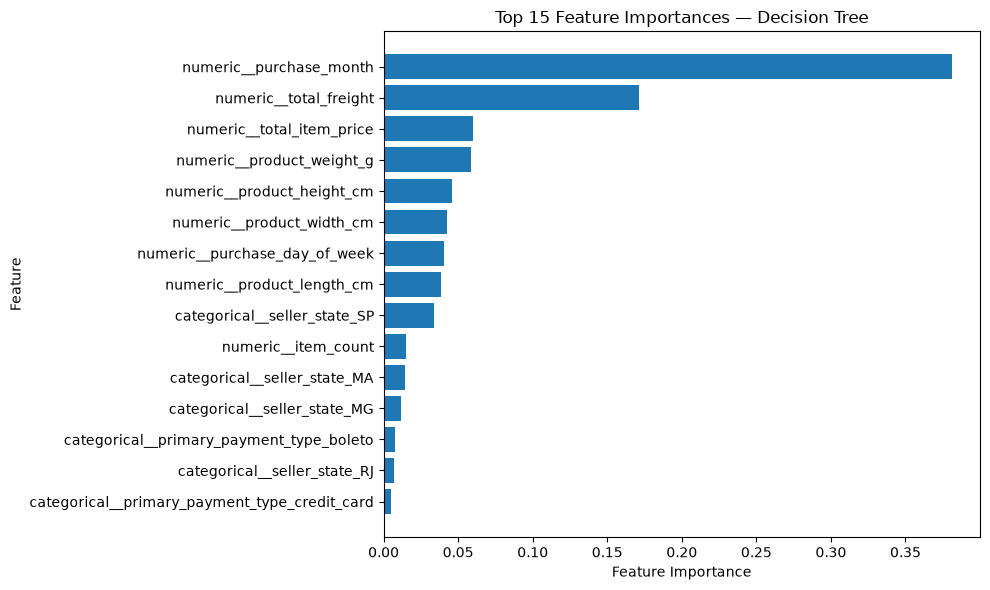

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve the fitted preprocessing and Decision Tree components.
fitted_preprocessor = dt_model.named_steps['preprocessor']
fitted_tree = dt_model.named_steps['classifier']

# Get the feature names after preprocessing and encoding.
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract the Decision Tree's feature importance scores.
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': fitted_tree.feature_importances_
})

# Display the 15 most important features.
importance_df = importance_df.sort_values(
    by='importance',
    ascending=False
)

print("Top 15 Important Features:")
print(importance_df.head(15).to_string(index=False))

# Plot the top 15 features for easier interpretation.
top_features = importance_df.head(15).sort_values(
    by='importance'
)

plt.figure(figsize=(10, 6))
plt.barh(top_features['feature'], top_features['importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importances — Decision Tree')
plt.tight_layout()
plt.show()

### Feature Importance — Key Observations

Purchase month was the most influential feature in the Decision Tree, followed by total freight charges and total item price. Product weight, dimensions, purchase day of the week, and selected seller-state categories also contributed to the model's predictions.

The prominence of purchase month suggests that temporal patterns may be useful for predicting delivery delays. Freight charges and product characteristics may also capture differences in shipping requirements.

These results represent predictive associations within the fitted Decision Tree. They do not establish causal relationships, and feature importance should not be interpreted as a measure of the direct effect of a variable on delivery delays.

Further investigation would be needed to determine whether these patterns remain stable across different time periods and models.

In [18]:
# Compare the baseline and both trained models using the same test set.
comparison_df = pd.DataFrame({
    'Model': [
        'Majority-Class Baseline',
        'Logistic Regression',
        'Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, dt_predictions)
    ],
    'Precision': [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, dt_predictions, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, dt_predictions, zero_division=0)
    ],
    'F1-score': [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, dt_predictions, zero_division=0)
    ]
})

# Round the metrics for easier comparison.
comparison_df = comparison_df.round(4)

print(comparison_df.to_string(index=False))

                  Model  Accuracy  Precision  Recall  F1-score
Majority-Class Baseline    0.9189     0.0000  0.0000    0.0000
    Logistic Regression    0.5283     0.0981  0.5879    0.1682
          Decision Tree    0.7036     0.1471  0.5534    0.2325


### Model Comparison — Results and Interpretation

Three models were evaluated on the same held-out test dataset.

- **Majority-Class Baseline:** Achieved 91.89% accuracy but failed to identify any late deliveries, resulting in an F1-score of zero for the delayed class.
- **Logistic Regression:** Achieved 58.79% recall for late deliveries but had low precision of 9.81%.
- **Decision Tree:** Achieved the highest F1-score of 0.2325 and precision of 14.71% among the three models, while maintaining 55.34% recall for late deliveries.

The Decision Tree provides the strongest overall balance of precision and recall in this initial comparison. However, its low precision means that most orders flagged as potentially delayed were not actually delayed.

The results demonstrate why accuracy alone is not an appropriate selection metric for an imbalanced classification problem. The Decision Tree is the preferred candidate for further investigation, but it is not yet suitable for operational deployment without additional validation and improvement.

## 5.5 Final Model Evaluation

The selected Decision Tree model will be evaluated using its confusion matrix to understand correct predictions, missed late deliveries, and false alarms.

This analysis helps translate classification metrics into operational implications for an e-commerce business.

In [19]:
# Calculate the Decision Tree's confusion matrix.
tn, fp, fn, tp = confusion_matrix(
    y_test, dt_predictions
).ravel()

# Summarize correct predictions and errors.
print("Decision Tree Error Analysis")
print("-" * 35)
print("Correctly identified on-time orders:", tn)
print("Incorrectly flagged on-time orders:", fp)
print("Missed late deliveries:", fn)
print("Correctly identified late deliveries:", tp)

# Calculate the percentage of flagged orders that were actually late.
flagged_orders = tp + fp

precision_percentage = (
    tp / flagged_orders * 100 if flagged_orders else 0
)

print(
    "\nPercentage of flagged orders that were actually late:",
    round(precision_percentage, 2), "%"
)

# Calculate the percentage of late deliveries the model missed.
actual_late_orders = tp + fn

missed_late_percentage = (
    fn / actual_late_orders * 100 if actual_late_orders else 0
)

print(
    "Percentage of late deliveries missed:",
    round(missed_late_percentage, 2), "%"
)

Decision Tree Error Analysis
-----------------------------------
Correctly identified on-time orders: 12709
Incorrectly flagged on-time orders: 5020
Missed late deliveries: 699
Correctly identified late deliveries: 866

Percentage of flagged orders that were actually late: 14.71 %
Percentage of late deliveries missed: 44.66 %


### Making a Prediction with the Trained Model

After training and evaluating the Decision Tree, the model can be used to predict delivery outcomes for individual orders.

In this demonstration, one order from the held-out test dataset will be selected. The model will predict whether the order is likely to be delayed and estimate the probability of each outcome.

The predicted outcome will then be compared with the known historical outcome to demonstrate how predictions can be evaluated.

In a real-world application, the model would receive features available at the intended prediction time and generate predictions for orders whose delivery outcomes are not yet known.

In [20]:
# Select one order from the test dataset.
sample_order = X_test.iloc[[0]]

# Predict whether the selected order will be delayed.
predicted_class = dt_model.predict(sample_order)[0]

# Obtain the estimated probability of each outcome.
predicted_probabilities = dt_model.predict_proba(sample_order)[0]

# Retrieve the actual historical outcome.
actual_class = y_test.loc[sample_order.index[0]]

# Display the prediction and compare it with the actual outcome.
print("Predicted outcome:",
      "Delayed" if predicted_class == 1 else "On time / Early")

print("Probability of on-time / early delivery:",
      round(predicted_probabilities[0] * 100, 2), "%")

print("Probability of late delivery:",
      round(predicted_probabilities[1] * 100, 2), "%")

print("Actual outcome:",
      "Delayed" if actual_class == 1 else "On time / Early")

print("Prediction correct:", predicted_class == actual_class)

Predicted outcome: On time / Early
Probability of on-time / early delivery: 65.8 %
Probability of late delivery: 34.2 %
Actual outcome: On time / Early
Prediction correct: True


### Evaluation Summary

Three models were evaluated on the same held-out test dataset: a Majority-Class Baseline, Logistic Regression, and Decision Tree.

The Majority-Class Baseline achieved 91.89% accuracy but failed to identify any late deliveries. Logistic Regression achieved 58.79% recall for late deliveries, while the Decision Tree achieved 55.34% recall and the highest F1-score of 0.2325.

The Decision Tree correctly identified 866 late deliveries and missed 699. It also incorrectly flagged 5,020 orders that were delivered on time or early. Only 14.71% of orders predicted as delayed were actually late.

The Decision Tree was the strongest candidate in this initial comparison based on precision and F1-score. However, both predictive models produced substantial false positives, limiting their current operational usefulness.

### Evaluation Conclusion

The initial experiments demonstrate that the available order features contain some predictive information about delivery delays. However, neither model is ready for operational deployment.

Further work should include validation on a later time period, improved feature engineering, and assessment of prediction thresholds against actual business costs.

## 5.6 Business Insights and Limitations

### Business Insights

**1. Delivery Delay Prediction**

The Decision Tree identified 55.34% of late deliveries in the test dataset. This suggests that the available order characteristics contain some predictive information about delivery outcomes.

**2. Temporal Patterns**

Purchase month was the most important feature in the fitted Decision Tree. This indicates that delivery outcomes may vary across different periods. Further analysis is needed to determine whether this pattern is stable and what factors may explain it.

**3. Shipping and Product Characteristics**

Total freight charges were the second most important feature, followed by total item price and several product dimensions. These variables may help distinguish orders with different delivery outcomes, although their importance does not establish causation.

**4. Potential Operational Application**

A future, improved version of the model could help prioritize orders for delivery-risk monitoring. However, the current model's low precision means that it would generate many false alarms if used directly for operational decisions.

### Model Limitations

**1. Low Precision**

Only 14.71% of orders predicted as delayed were actually late. Most flagged orders were delivered on time or early.

**2. Missed Late Deliveries**

The model failed to identify 44.66% of actual late deliveries. This limits its ability to detect all orders at risk.

**3. Imbalanced Target**

Only 8.11% of eligible orders were delayed. This class imbalance makes it important to evaluate recall, precision, and F1-score alongside accuracy.

**4. Feature Representation**

For orders containing multiple items, the current aggregation retains the first seller state and product category. This may not adequately represent orders containing products from different sellers or categories.

**5. Prediction Timing**

The model uses order characteristics intended to be available near purchase. Before practical deployment, every feature must be verified as available at the exact time a prediction would be made.

**6. Validation on Future Orders**

The current evaluation uses a random train-test split. A chronological train-test split would provide a stronger assessment of performance on orders from a later period.

**7. No Causal Conclusions**

Feature importance indicates which variables the fitted model relied on. It does not prove that those variables cause delivery delays.

### Overall Conclusion

RetailIQ demonstrates an introductory machine learning workflow, from defining a business prediction problem to preparing data, training models, evaluating predictions, and interpreting results.

The Decision Tree achieved the highest F1-score among the models tested, but its current performance is insufficient for operational deployment. Better feature engineering, chronological validation, and further model evaluation are recommended as future improvements.

## 5.7 Documentation and Conclusion

### Project Summary

RetailIQ's machine learning phase explored whether historical order characteristics could help predict late deliveries in an e-commerce environment.

The workflow included:

- Defining a business prediction problem and binary target.
- Preparing an order-level modeling dataset.
- Establishing a majority-class baseline.
- Training and comparing Logistic Regression and Decision Tree classifiers.
- Evaluating model performance using classification metrics and a confusion matrix.
- Examining feature importance and demonstrating an individual prediction.
- Identifying potential business applications and model limitations.

### Final Model Results

The Decision Tree achieved an accuracy of 70.36%, precision of 14.71%, recall of 55.34%, and F1-score of 23.25% for late deliveries. It achieved the highest F1-score among the models evaluated.

Purchase month and total freight charges were the two most important features in the fitted Decision Tree.

### Final Conclusion

The experiments demonstrate that the available order features contain some information useful for predicting delivery delays. However, the model's low precision and substantial number of false positives limit its current operational usefulness.

The project should be considered an exploratory machine learning exercise rather than a production-ready prediction system. Future improvements could include richer order-level features, chronological validation, probability-threshold analysis, and further model refinement.

This phase completes the planned introductory machine learning workflow for RetailIQ.